# How a Python dictionary finds a key: look inside your own

The companion to `notes.pdf`. Every cell reads something real from the Python running it: the number `hash()`
gives a key, the slot that number picks, the slots and entries of a live dictionary (read from memory with
`ctypes`, Python's module for reading raw memory), how many keys a lookup compares, the size of the table as it
grows, a set's order, and a key that gets lost. Standard library only; the whole notebook runs in seconds.
`FULL = True` repeats the compare count at the notes' size (1,000,000 keys).

Our run, for comparison: CPython 3.12.7 on arm64. For text, `hash()` mixes in a secret number (a
*salt*) that changes every time Python starts, so where a cell must match the video it asks a fresh Python
started with `PYTHONHASHSEED=0`, which turns the salt off. Everything else uses this kernel's own salt: your slots
will differ from ours, and the rules won't.

The big dictionary in section 4 maps made-up email addresses to user ids. Each address pairs a common first name
with a common last name at a big mail provider, so the keys look real without being anyone's.

In [1]:
FULL = False                      # True: count compares in a dictionary of 1,000,000 keys, as in the notes
N = 1_000_000 if FULL else 100_000

import ctypes
import json
import os
import platform
import random
import subprocess
import sys
import sysconfig
from dataclasses import dataclass

try:
    import matplotlib.pyplot as plt
except ImportError:               # the chart is optional; every cell also prints its numbers
    plt = None

KEYS = ["leo", "ana", "zoe", "ivy", "kai", "tom"]   # the lesson's dictionary, in insertion order
AGES = [31, 27, 45, 19, 38, 52]
MISSING = "ron"

FIRST = """emma olivia sophia mia isabella amelia ella grace chloe lily hannah sarah anna laura julia maria sofia lucia
elena carmen paula camila valentina gabriela daniela aigerim aliya madina zarina dinara amina fatima leila yasmin
nora ingrid freya astrid mei yuki hana minji priya ananya aisha zainab james john michael david daniel matthew
andrew ryan ethan noah liam lucas mason jacob william thomas oliver jack henry samuel benjamin alexander leon felix
jonas lukas paul marco luca matteo diego carlos javier pablo miguel mateo santiago arman timur daniyar aidar askar
omar ali hassan karim yusuf ivan dmitri kenji haruto minho wei jun raj arjun rohan kwame kofi tunde""".split()
LAST = """smith johnson williams brown jones miller davis wilson anderson taylor thomas moore martin jackson white
harris clark lewis walker hall young king wright scott green baker adams nelson hill campbell garcia rodriguez
martinez hernandez lopez gonzalez perez sanchez ramirez torres flores rivera gomez diaz morales ortiz castro silva
santos oliveira costa pereira rossi russo ferrari bianchi romano mueller schmidt schneider fischer weber meyer
wagner becker novak kowalski nowak ivanov petrov popov volkov kim lee park choi kang tanaka suzuki sato watanabe
wang zhang liu chen yang nguyen tran patel sharma singh kumar khan ahmed ibrahim mensah okafor adeyemi nurlanov
akhmetov omarov bekov suleimenov""".split()
DOMAINS = ["gmail.com", "yahoo.com", "outlook.com", "icloud.com", "hotmail.com", "proton.me"]
WEIGHTS = [50, 12, 12, 10, 10, 6]
NOBODY = "rosa.mendes@proton.me"                    # never generated: rosa is not in FIRST


def emails(n, seed=2026):
    """n distinct made-up addresses: name pair i mod P of a shuffled list, with i // P on the end when not 0."""
    rng = random.Random(seed)
    pairs = [f"{f}.{l}" for f in FIRST for l in LAST]
    rng.shuffle(pairs)
    domains = rng.choices(DOMAINS, weights=WEIGHTS, k=n)
    return [f"{pairs[i % len(pairs)]}{i // len(pairs) or ''}@{domains[i]}" for i in range(n)]


def fresh(code: str, seed=None) -> str:
    """Run `code` in a brand-new Python; seed=None leaves PYTHONHASHSEED unset (a random salt)."""
    env = {k: v for k, v in os.environ.items() if k != "PYTHONHASHSEED"}
    if seed is not None:
        env["PYTHONHASHSEED"] = str(seed)
    return subprocess.run([sys.executable, "-c", code], env=env, capture_output=True, text=True,
                          check=True).stdout.strip()


print(platform.python_implementation(), platform.python_version(), platform.machine(),
      "| str hash:", sys.hash_info.algorithm, "| PYTHONHASHSEED:", os.environ.get("PYTHONHASHSEED", "random"),
      "| N =", f"{N:,}")

CPython 3.12.7 arm64 | str hash: siphash13 | PYTHONHASHSEED: random | N = 100,000


## 1. `hash()` turns a key into one big number

A *hash function* turns a value into one whole number, its *hash*: the same key always gives the same number,
and two different keys rarely give the same one. Look at three things below: the same key gives the same number
inside one running Python (one *process*); a fresh process gives a new number for a `str` (the salt); a fixed
`PYTHONHASHSEED` gives the same number every time. Our three fresh runs gave -3106019050841923564, 824631066563492447, -1481560786574505415; with
the seed fixed to 0, `hash("leo")` was 6416341914839982780. Numbers are not salted: `hash(31)`
is 31.

In [2]:
print('hash("leo") in this kernel:', hash("leo"), "| again:", hash("leo"))
for _ in range(3):
    print("fresh Python, random salt:     ", fresh('print(hash("leo"))'))
for _ in range(2):
    print("fresh Python, PYTHONHASHSEED=0:", fresh('print(hash("leo"))', seed=0))
print("hash(31) =", hash(31), "| hash(-1) =", hash(-1), "(-1 means 'error' to the C code)",
      "| hash(1) == hash(1.0) == hash(True):", hash(1) == hash(1.0) == hash(True))

hash("leo") in this kernel: -8126751754383816851 | again: -8126751754383816851
fresh Python, random salt:      232138196173036455
fresh Python, random salt:      -4244102619140757874
fresh Python, random salt:      -1319246672795504156
fresh Python, PYTHONHASHSEED=0: 6416341914839982780
fresh Python, PYTHONHASHSEED=0: 6416341914839982780
hash(31) = 31 | hash(-1) = -2 (-1 means 'error' to the C code) | hash(1) == hash(1.0) == hash(True): True


## 2. The slot is the hash's last bits: `hash & 7`

A dictionary keeps its keys in a row of numbered boxes, *slots*; a new one has 8. The slot number is the
remainder of the hash divided by 8, which in binary is just the last three bits (digits) of the hash:
`hash & 7`. A table's size is always a power of two, so in general the slot is `hash & (size - 1)`. With the
video's seed, `"leo"` ends in `…10111100`, slot 4; `"kai"` ends in
`…10000100`, slot 4 too: that's the collision in section 5. The last
line is the same keys under this kernel's own salt.

In [3]:
H0 = dict(zip(KEYS + [MISSING],
              json.loads(fresh(f"import json; print(json.dumps([hash(k) for k in {KEYS + [MISSING]!r}]))", seed=0))))
print("PYTHONHASHSEED=0 (the video):")
for k, h in H0.items():
    print(f"  {k!r:6} {h:>21}   …{h & 0xFF:08b}   & 7 = {h & 7}   & 15 = {h & 15:>2}")
print("this kernel:", {k: hash(k) & 7 for k in KEYS + [MISSING]})

PYTHONHASHSEED=0 (the video):
  'leo'    6416341914839982780   …10111100   & 7 = 4   & 15 = 12
  'ana'    6689456082293094062   …10101110   & 7 = 6   & 15 = 14
  'zoe'    4753751193158421501   …11111101   & 7 = 5   & 15 = 13
  'ivy'    7073951147871596880   …01010000   & 7 = 0   & 15 =  0
  'kai'    2191149455901616516   …10000100   & 7 = 4   & 15 =  4
  'tom'    3107437652009736866   …10100010   & 7 = 2   & 15 =  2
  'ron'    8031059091648294011   …01111011   & 7 = 3   & 15 = 11
this kernel: {'leo': 5, 'ana': 6, 'zoe': 3, 'ivy': 7, 'kai': 3, 'tom': 2, 'ron': 7}


## 3. Inside a real dictionary: the slots and the entries

A dictionary is two arrays. The **slots** hold `-1` (empty) or an entry number; the **entries** hold the keys
and values in the order they went in. The reader below takes both straight out of memory (the CPython 3.11+
layout, 64-bit) and checks every read against `len()`, the dictionary's own keys and values, and a replay of
CPython's placement rule; on any other build it says so, and the cells fall back to the replay alone. In the
printout, `.` is an empty slot and `x` a deleted one.

In our run, after four inserts the slots were `[3, -1, -1, -1, 0, 2, 1, -1]`, and after the sixth
insert the table had 16 slots with leo in slot 12.

In [4]:
U64, EMPTY, DUMMY = (1 << 64) - 1, -1, -2


def probe(h: int, mask: int):
    """The slots a key visits in a dict, in order (Objects/dictobject.c)."""
    perturb, i = h & U64, h & mask
    while True:
        yield i
        perturb >>= 5
        i = (5 * i + 1 + perturb) & mask


def place(hashes, size):
    """The slots CPython fills when entries with these hashes go in, in this order."""
    slots = [EMPTY] * size
    for n, h in enumerate(hashes):
        slots[next(i for i in probe(h, size - 1) if slots[i] == EMPTY)] = n
    return slots


def word(addr):
    return ctypes.c_ssize_t.from_address(addr).value


def read_dict(d: dict) -> dict:
    """{'size', 'slots', 'entries', 'usable', 'stored_hashes'} read from the dict's memory, or ValueError."""
    if sys.implementation.name != "cpython" or sys.maxsize != 2**63 - 1 or sys.version_info < (3, 11) \
            or sysconfig.get_config_var("Py_GIL_DISABLED"):
        raise ValueError("this reader knows the 64-bit CPython 3.11+ layout only")
    used, keys, values = word(id(d) + 16), word(id(d) + 32), word(id(d) + 40)
    if used != len(d) or values or not keys:
        raise ValueError("the header doesn't match len(d)")
    log2_size, log2_index, kind = (ctypes.c_uint8.from_address(keys + off).value for off in (8, 9, 10))
    usable, nentries = word(keys + 16), word(keys + 24)
    if len(d) == 0:
        return {"size": 0, "slots": [], "entries": [], "usable": usable, "stored_hashes": []}
    size, width = 1 << log2_size, (1 << log2_index) >> log2_size
    ix = {1: ctypes.c_int8, 2: ctypes.c_int16, 4: ctypes.c_int32, 8: ctypes.c_int64}[width]
    slots = [ix.from_address(keys + 32 + width * i).value for i in range(size)]
    step = 16 if kind == 1 else 24                       # {key, value} for all-str keys, else {hash, key, value}
    at = keys + 32 + (1 << log2_index)
    items = list(d.items())
    ptrs = [(word(at + step * n + step - 16), word(at + step * n + step - 8)) for n in range(nentries)]
    live = [p for p in ptrs if p[0]]
    if live != [(id(k), id(v)) for k, v in items]:
        raise ValueError("the entries don't match the dict's keys and values")
    stored = [word(at + step * n) for n in range(nentries) if ptrs[n][0]] if kind != 1 else []
    return {"size": size, "slots": slots, "entries": [(k, v) for k, v in items], "usable": usable,
            "stored_hashes": stored}


def show(t):
    cells = " ".join("." if s == EMPTY else "x" if s == DUMMY else str(s) for s in t["slots"])
    print(f"   slots [{cells}]   entries {[k for k, _ in t['entries']]}   {t['usable']} more fit")


ages = {}
try:
    read_dict(ages)
    READ = True
except ValueError as e:
    READ = False
    print("memory reads skipped:", e)

for k, v in zip(KEYS, AGES):
    ages[k] = v
    print(f"ages[{k!r}] = {v}   getsizeof {sys.getsizeof(ages)} bytes")
    if READ:
        t = read_dict(ages)
        show(t)
        assert t["slots"] == place([hash(x) for x in ages], t["size"]), "real table != replay"
print("\nlist(ages):", list(ages), " ← the entries, in insertion order")
print("video's seed, replayed: 4 keys →", place([H0[k] for k in KEYS[:4]], 8))
print("                        6 keys →", place([H0[k] for k in KEYS], 16))

ages['leo'] = 31   getsizeof 184 bytes
   slots [. . . . . 0 . .]   entries ['leo']   4 more fit
ages['ana'] = 27   getsizeof 184 bytes
   slots [. . . . . 0 1 .]   entries ['leo', 'ana']   3 more fit
ages['zoe'] = 45   getsizeof 184 bytes
   slots [. . . 2 . 0 1 .]   entries ['leo', 'ana', 'zoe']   2 more fit
ages['ivy'] = 19   getsizeof 184 bytes
   slots [. . . 2 . 0 1 3]   entries ['leo', 'ana', 'zoe', 'ivy']   1 more fit
ages['kai'] = 38   getsizeof 184 bytes
   slots [. 4 . 2 . 0 1 3]   entries ['leo', 'ana', 'zoe', 'ivy', 'kai']   0 more fit
ages['tom'] = 52   getsizeof 272 bytes
   slots [. . 5 2 . . 1 . . 4 . . . 0 . 3]   entries ['leo', 'ana', 'zoe', 'ivy', 'kai', 'tom']   4 more fit

list(ages): ['leo', 'ana', 'zoe', 'ivy', 'kai', 'tom']  ← the entries, in insertion order
video's seed, replayed: 4 keys → [3, -1, -1, -1, 0, 2, 1, -1]
                        6 keys → [3, -1, 5, -1, 4, -1, -1, -1, -1, -1, -1, -1, 0, 2, 1, -1]


## 4. A lookup compares one key

The lookup hashes the key, goes to its slot, follows it to an entry, and checks: the same object (`is`)? the same
hash? only then `==`, which calls the key's `__eq__` method. A key class that counts its `__eq__` calls shows how
many keys Python really compared, here in a dictionary of `N` email addresses mapped to user ids. In our run,
with 1,000,000 keys, a hit compared 1 key and a miss compared
0.

In [5]:
class Key:
    """An email address that counts how many times Python compares it with another key."""
    __slots__ = ("s",)
    eq_calls = 0

    def __init__(self, s):
        self.s = s

    def __hash__(self):
        return hash(self.s)

    def __eq__(self, other):
        Key.eq_calls += 1
        return isinstance(other, Key) and self.s == other.s


addresses = emails(N)
users = {Key(e): user_id for user_id, e in enumerate(addresses)}
target = addresses[424242 % N]
Key.eq_calls = 0
print(f"users[Key({target!r})] = {users[Key(target)]}   keys compared: {Key.eq_calls}"
      f"   (a dictionary of {len(users):,} keys)")
Key.eq_calls = 0
print(f"Key({NOBODY!r}) in users = {Key(NOBODY) in users}   keys compared: {Key.eq_calls}")
del users

users[Key('astrid.white2@gmail.com')] = 24242   keys compared: 1   (a dictionary of 100,000 keys)
Key('rosa.mendes@proton.me') in users = False   keys compared: 0


## 5. A collision: the next slot comes from the hash

Two keys that want the same slot are a *collision*. With the video's seed, kai's slot 4
already points to leo's entry. CPython mixes in the hash's higher bits: `perturb` starts
as the hash, shifts right by 5 bits at every step, and the next slot is `(5 * slot + 1 + perturb) & 7`:
1 in our run. Once `perturb` has shifted down to 0, `5 * i + 1` alone walks every slot
of a power-of-two table, so an empty one is always found.

In [6]:
h = H0["kai"]
path = []
for i in probe(h, 7):
    path.append(i)
    if len(path) == 2:
        break
print(f"kai: hash & 7 = {path[0]} (taken by leo), perturb = hash >> 5 = {(h & U64) >> 5}")
print(f"     (5 * {path[0]} + 1 + perturb) & 7 = {path[1]}")

i, walk = 0, []
for _ in range(8):
    walk.append(i)
    i = (5 * i + 1) & 7
print("5 * i + 1, mod 8, from slot 0:", walk, "→ every slot once:", sorted(walk) == list(range(8)))

kai: hash & 7 = 4 (taken by leo), perturb = hash >> 5 = 68473420496925516
     (5 * 4 + 1 + perturb) & 7 = 1
5 * i + 1, mod 8, from slot 0: [0, 1, 6, 7, 4, 5, 2, 3] → every slot once: True


## 6. The resize: `getsizeof` across inserts

A table is never allowed past about two-thirds full: 8 slots take 5 keys. The sixth insert
rebuilds the table with 16 slots and places every key again: `sys.getsizeof`, the bytes
of the dictionary and its table, went 184 → 272 in our run.
After that a dictionary of `str` keys jumped at
1, 6, 11, 22, 43, 86 keys; a set (three-fifths full, then four times
bigger) at 5, 19, 77.

dict: (keys, bytes) at each jump: [(0, 64), (1, 184), (6, 272), (11, 464), (22, 832), (43, 1584), (86, 3328)]
set:  (items, bytes) at each jump: [(0, 216), (5, 728), (19, 2264), (77, 8408)]
   dict at   1 keys:   8 slots
   dict at   6 keys:  16 slots
   dict at  11 keys:  32 slots
   dict at  22 keys:  64 slots
   dict at  43 keys: 128 slots
   dict at  86 keys: 256 slots


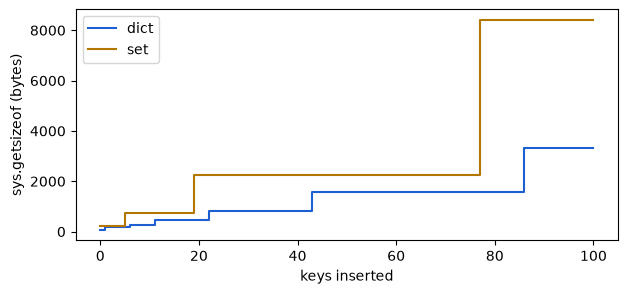

In [7]:
GROW_KEYS = emails(100)


def jumps(make, add, upto=100):
    obj, out, last = make(), [], None
    for n in range(upto + 1):
        if n:
            add(obj, GROW_KEYS[n - 1])
        size = sys.getsizeof(obj)
        if size != last:
            out.append((n, size))
            last = size
    return out


dict_jumps = jumps(dict, lambda d, k: d.__setitem__(k, None))
set_jumps = jumps(set, set.add)
print("dict: (keys, bytes) at each jump:", dict_jumps)
print("set:  (items, bytes) at each jump:", set_jumps)
if READ:
    probe_d = {}
    for n in range(1, 101):
        probe_d[GROW_KEYS[n - 1]] = None
        if n in [j for j, _ in dict_jumps]:
            print(f"   dict at {n:>3} keys: {read_dict(probe_d)['size']:>3} slots")

if plt:
    fig, ax = plt.subplots(figsize=(7, 3))
    for label, js, color in (("dict", dict_jumps, "#1D5FD0"), ("set", set_jumps, "#B57600")):
        xs = [n for n, _ in js] + [100]
        ax.step(xs, [b for _, b in js] + [js[-1][1]], where="post", label=label, color=color)
    ax.set_xlabel("keys inserted")
    ax.set_ylabel("sys.getsizeof (bytes)")
    ax.legend()
    plt.show()

## 7. A set's order is its slot order

A set is the same table without values, and it has no entries array: its slots hold the elements, and
`for x in s` walks the slots. Small whole numbers are their own hashes, so you can predict a small set's order by
hand; strings move with the salt, so a set of names can print in a new order in each process, while a dictionary
of the same names doesn't. One more element can reorder a set too: the table grew, and every element was placed
again.

In [8]:
def set_slots(s):
    used, mask, table = word(id(s) + 24), word(id(s) + 32), word(id(s) + 40)
    if used != len(s) or (mask + 1) & mask:
        raise ValueError("unexpected set layout")
    by_id = {id(x): x for x in s}
    return [by_id.get(ctypes.c_void_p.from_address(table + 16 * i).value) for i in range(mask + 1)]


s = {12, 3, 7, 1}
print("set {12, 3, 7, 1}: n & 7 =", [n & 7 for n in (12, 3, 7, 1)], "→ list(s) =", list(s))
if READ:
    print("   the real slots:", set_slots(s))
s = {16, 1, 2, 3}
print("{16, 1, 2, 3} →", list(s), end="   ")
s.add(4)
print("after .add(4) →", list(s), "(it grew: 16 & 31 = 16)")

code = f"n = {KEYS[:5]!r}; print(list(set(n)), list(dict.fromkeys(n)))"
for _ in range(3):
    print("fresh Python:", fresh(code))

set {12, 3, 7, 1}: n & 7 = [4, 3, 7, 1] → list(s) = [1, 3, 12, 7]
   the real slots: [None, 1, None, 3, 12, None, None, 7]
{16, 1, 2, 3} → [16, 1, 2, 3]   after .add(4) → [1, 2, 3, 4, 16] (it grew: 16 & 31 = 16)


fresh Python: ['zoe', 'kai', 'ivy', 'ana', 'leo'] ['leo', 'ana', 'zoe', 'ivy', 'kai']
fresh Python: ['ivy', 'zoe', 'ana', 'leo', 'kai'] ['leo', 'ana', 'zoe', 'ivy', 'kai']
fresh Python: ['ana', 'ivy', 'zoe', 'leo', 'kai'] ['leo', 'ana', 'zoe', 'ivy', 'kai']


## 8. A key's hash must never change

The slot is picked once, from the hash the key had when it went in. A list can change after that (it is
*mutable*), so it has no hash: `TypeError: unhashable type: 'list'`. To see why, the class below hashes its list,
the way a hashable list would. In our run the key went into slot 5; after
`.append("sam")` its hash pointed to slot 3, `t in d` was
False, and the key was still inside.

In [9]:
try:
    {}[["leo", "ana"]] = 31
except TypeError as e:
    print("list as a key  →", f"TypeError: {e}")
print("tuple as a key →", {("leo", "ana"): 31})


class Tag:
    def __init__(self, parts):
        self.parts = parts

    def __hash__(self):
        return hash(tuple(self.parts))

    def __eq__(self, other):
        return isinstance(other, Tag) and self.parts == other.parts


t = Tag(["leo"])
d = {t: 31}
print(f"\nhash(t) & 7 = {hash(t) & 7}", "| stored hash in the entry:", read_dict(d)["stored_hashes"] if READ else "-")
t.parts.append("sam")
print(f"after append: hash(t) & 7 = {hash(t) & 7}", "| stored hash:", read_dict(d)["stored_hashes"] if READ else "-",
      "| hash(t) now:", hash(t))
print("t in d:", t in d, "| still inside:", any(k is t for k in d), "| len(d):", len(d))


@dataclass(frozen=True)
class Point:
    x: int
    y: int


print("\nfrozen dataclass as a key:", Point(1, 2) in {Point(1, 2): "here"})
print("{1: 'a', True: 'b', 1.0: 'c'} →", {1: "a", True: "b", 1.0: "c"})

list as a key  → TypeError: unhashable type: 'list'
tuple as a key → {('leo', 'ana'): 31}

hash(t) & 7 = 2 | stored hash in the entry: [3540429351239048650]
after append: hash(t) & 7 = 6 | stored hash: [3540429351239048650] | hash(t) now: 8888439033252224862
t in d: False | still inside: True | len(d): 1

frozen dataclass as a key: True
{1: 'a', True: 'b', 1.0: 'c'} → {1: 'c'}


## Your turn

1. **Delete a key and look at the slots.** Run `del ages["leo"]`, then `show(read_dict(ages))`: leo's slot now
   holds `x`, a dummy (`-2`), not `.`. Why can't it go back to empty? (Hint: with the video's seed, kai's path
   ran through leo's slot 4 before it reached its own.) Keep inserting new keys until
   the table is rebuilt, and watch the dummy disappear.
2. **Break the hash.** Give `Key` a `__hash__` that returns `hash(self.s) % 4`, rebuild `users` from a few
   thousand addresses, and count the keys a hit compares now. Then try `% 1000`. What does the count tell you
   about how much of the hash a dictionary really needs?